# Definir preguntas de negocio/insights a responder

- ¿Netflix tiene más películas o series?
- ¿Qué países producen más contenido?
- ¿Cómo ha crecido el catálogo por año (year_added)?
- ¿Qué géneros (listed_in) son los más comunes?
- ¿Cuál es la duración promedio de películas vs. número de temporadas de series?
- ¿Qué clasificaciones (rating) predominan?

In [1]:
# Manejo de datos
import pandas as pd
import numpy as np
# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
# Para que los gráficos se vean dentro del notebook (comando mágico, solo funciona aquí, no en .py)
%matplotlib inline
#Mejora el estilo visual de los gráficos de seaborn
sns.set_style('whitegrid')

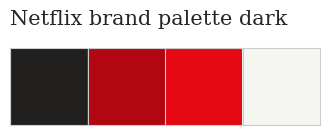

In [4]:
# Palette
sns.palplot(['#221f1f', '#b20710', '#e50914','#f5f5f1'])
plt.title("Netflix brand palette dark ",loc='left',fontfamily='serif',fontsize=15,y=1.2)
plt.show()

In [2]:
# Cargar el dataset limpio
df = pd.read_csv('../data/processed/netflix_titles_clean.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_int,duration_type,year_added,month_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,No Data,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0,min,2021.0,9.0
1,s2,TV Show,Blood & Water,No Data,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2.0,Seasons,2021.0,9.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",United States,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1.0,Season,2021.0,9.0
3,s4,TV Show,Jailbirds New Orleans,No Data,No Data,United States,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1.0,Season,2021.0,9.0
4,s5,TV Show,Kota Factory,No Data,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2.0,Seasons,2021.0,9.0


## Ratio Show/Pelicula

In [5]:
# Cuenta cuántas filas hay de cada 'type' (Movie / TV Show)
x = df.groupby(['type'])['type'].count()
# Total de filas del DataFrame completo
y = len(df)
# Calcula la proporción de cada tipo sobre el total, redondeado a 2 decimales
# Ejemplo: si hay 6000 Movies de 8790 filas → 0.68 (68%)
r = ((x/y)).round(2)
# Convierte la Serie en un DataFrame de una sola fila, usando .T (transponer)
# Esto lo deja en formato "ancho": columnas = Movie, TV Show | una sola fila de valores
mf_ratio = pd.DataFrame(r).T

C:\Users\psimeon\AppData\Local\Temp\ipykernel_9200\459054153.py:14: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.text(mf_ratio['Movie'][0]/2, 0, f"{mf_ratio['Movie'][0]*100:.0f}%\nMovie",
C:\Users\psimeon\AppData\Local\Temp\ipykernel_9200\459054153.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  ax.text(mf_ratio['Movie'][0] + mf_ratio['TV Show'][0]/2, 0, f"{mf_ratio['TV Show'][0]*100:.0f}%\nTV Show",


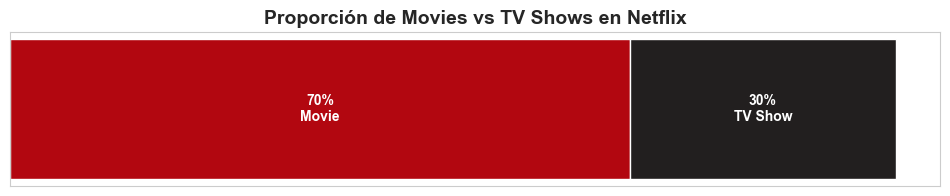

In [6]:
#Crear la figura y los ejes
fig, ax = plt.subplots(1, 1, figsize=(12, 2))
# Dibuja la parte de "Movie" desde 0 hasta su proporción
ax.barh(mf_ratio.index, mf_ratio['Movie'], color='#b20710', label='Movie')

# Dibuja la parte de "TV Show" empegada justo después de Movie (left=...)
ax.barh(mf_ratio.index, mf_ratio['TV Show'], left=mf_ratio['Movie'], color='#221f1f', label='TV Show')

# Quita ejes para que se vea limpio, como infografía
ax.set_xticks([])
ax.set_yticks([])

# Agrega el porcentaje como texto dentro de cada barra
ax.text(mf_ratio['Movie'][0]/2, 0, f"{mf_ratio['Movie'][0]*100:.0f}%\nMovie", 
        ha='center', va='center', color='white', fontweight='bold')
ax.text(mf_ratio['Movie'][0] + mf_ratio['TV Show'][0]/2, 0, f"{mf_ratio['TV Show'][0]*100:.0f}%\nTV Show", 
        ha='center', va='center', color='white', fontweight='bold')

ax.set_title("Proporción de Movies vs TV Shows en Netflix", fontweight='bold', fontsize=14)
plt.show()


## ¿Qué países producen más contenido?

In [7]:
# Paso 1: separa el texto de 'country' por comas, convirtiendo cada celda en una lista
df['country_lista'] = df['country'].str.split(',')

# Paso 2: quita espacios en blanco sobrantes de cada país en la lista
df['country_lista'] = df['country_lista'].apply(lambda lista: [pais.strip() for pais in lista])

# Paso 3: "explota" la lista en filas individuales (un país por fila)
df_paises = df.explode('country_lista')

# Paso 4: cuenta cuántas veces aparece cada país, y toma el top 10
top_paises = df_paises['country_lista'].value_counts().head(10)

print(top_paises)


country_lista
United States     4510
India             1046
United Kingdom     805
Canada             445
France             393
Japan              316
Spain              232
South Korea        231
Germany            226
Mexico             169
Name: count, dtype: int64


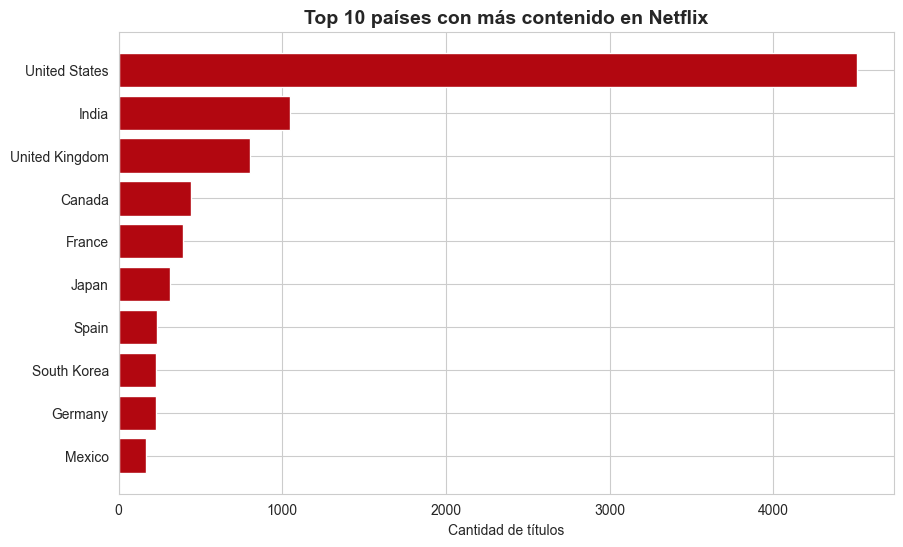

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

# Gráfico de barras horizontales (más fácil de leer nombres de países largos)
# [::-1] invierte el orden para que el país #1 quede arriba
ax.barh(top_paises.index[::-1], top_paises.values[::-1], color='#b20710')

ax.set_xlabel('Cantidad de títulos')
ax.set_title('Top 10 países con más contenido en Netflix', fontweight='bold', fontsize=14)

plt.show()


## ¿Cómo ha crecido el catálogo por año (year_added)?

In [9]:
# Cuenta cuántos títulos se agregaron por año
titulos_por_año = df['year_added'].value_counts().sort_index()
print(titulos_por_año)


year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      10
2014.0      23
2015.0      73
2016.0     415
2017.0    1161
2018.0    1624
2019.0    1999
2020.0    1878
2021.0    1498
Name: count, dtype: int64


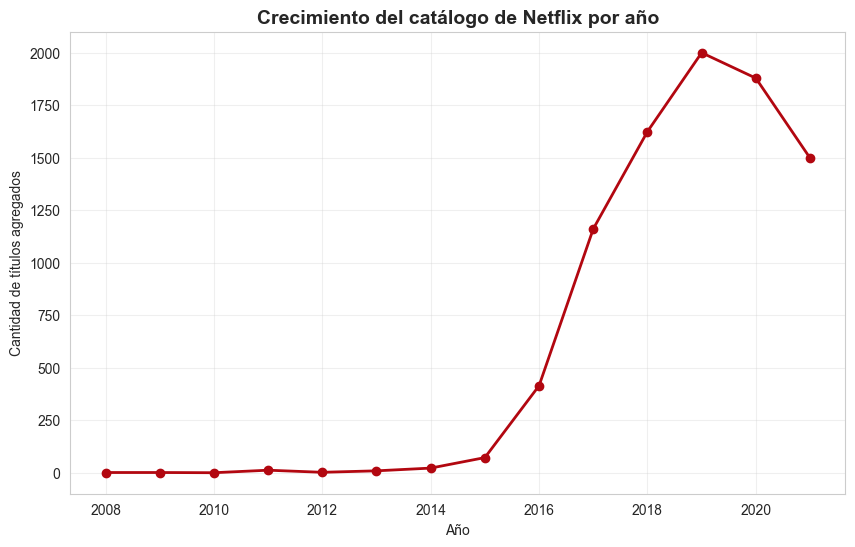

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(titulos_por_año.index, titulos_por_año.values, marker='o', color='#b20710', linewidth=2)
ax.set_xlabel('Año')
ax.set_ylabel('Cantidad de títulos agregados')
ax.set_title('Crecimiento del catálogo de Netflix por año', fontweight='bold', fontsize=14)
ax.grid(True, alpha=0.3)

plt.show()


In [11]:
# Agrupa por año Y tipo, contando cuántos hay de cada combinación
crecimiento_por_tipo = df.groupby(['year_added', 'type'])['type'].count().unstack()
print(crecimiento_por_tipo)


type         Movie  TV Show
year_added                 
2008.0         1.0      1.0
2009.0         2.0      NaN
2010.0         1.0      NaN
2011.0        13.0      NaN
2012.0         3.0      NaN
2013.0         6.0      4.0
2014.0        19.0      4.0
2015.0        56.0     17.0
2016.0       251.0    164.0
2017.0       836.0    325.0
2018.0      1237.0    387.0
2019.0      1424.0    575.0
2020.0      1284.0    594.0
2021.0       993.0    505.0


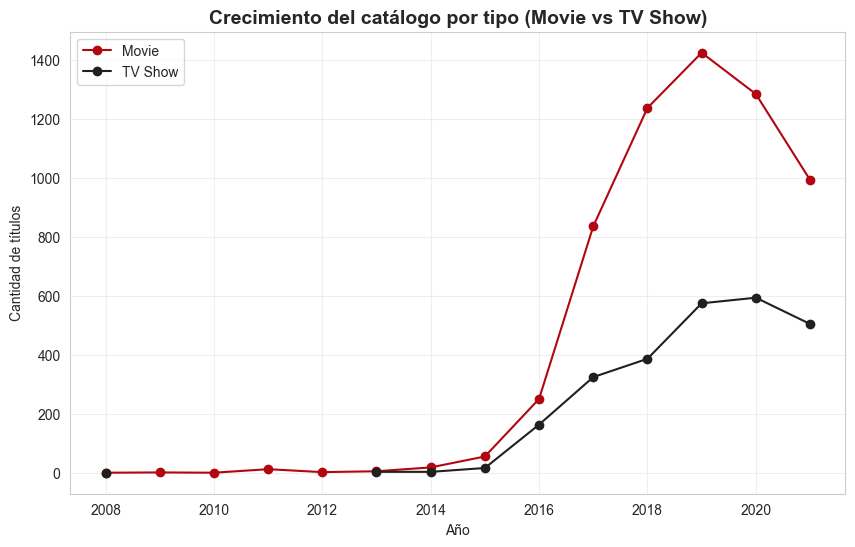

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(crecimiento_por_tipo.index, crecimiento_por_tipo['Movie'], marker='o', label='Movie', color='#b20710')
ax.plot(crecimiento_por_tipo.index, crecimiento_por_tipo['TV Show'], marker='o', label='TV Show', color='#221f1f')

ax.set_xlabel('Año')
ax.set_ylabel('Cantidad de títulos')
ax.set_title('Crecimiento del catálogo por tipo (Movie vs TV Show)', fontweight='bold', fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()


In [19]:
# Filtra solo las filas donde el país es India
df_india = df_paises[df_paises['country_lista'] == 'India']

# Cuenta cuántos títulos se agregaron por año
crecimiento_india = df_india['year_added'].value_counts().sort_index()

print(crecimiento_india)


year_added
2016.0     13
2017.0    161
2018.0    349
2019.0    218
2020.0    199
2021.0    105
Name: count, dtype: int64


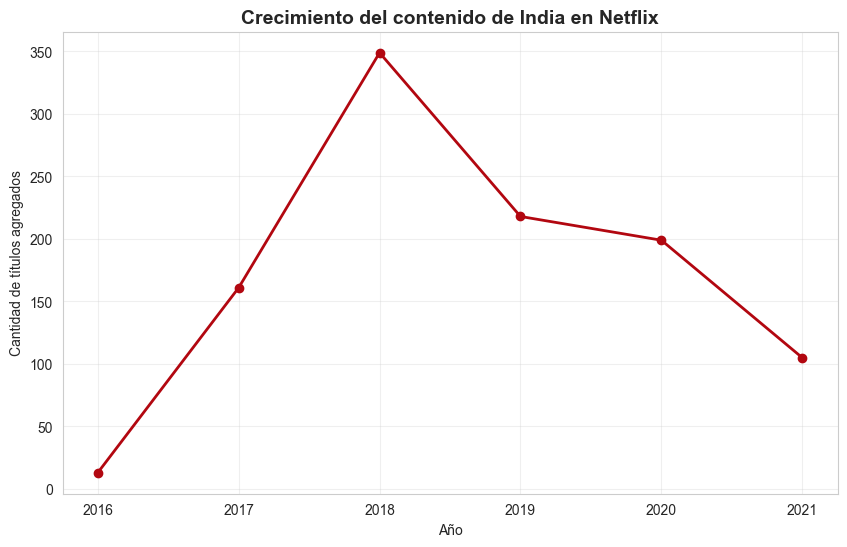

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(crecimiento_india.index, crecimiento_india.values, marker='o', color='#b20710', linewidth=2)

ax.set_xlabel('Año')
ax.set_ylabel('Cantidad de títulos agregados')
ax.set_title('Crecimiento del contenido de India en Netflix', fontweight='bold', fontsize=14)
ax.grid(True, alpha=0.3)

plt.show()


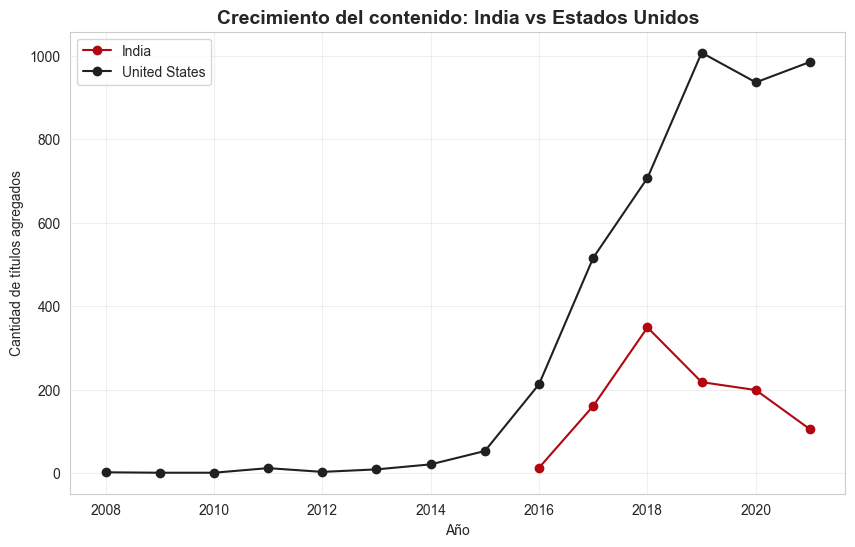

In [21]:
df_us = df_paises[df_paises['country_lista'] == 'United States']
crecimiento_us = df_us['year_added'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(crecimiento_india.index, crecimiento_india.values, marker='o', label='India', color='#b20710')
ax.plot(crecimiento_us.index, crecimiento_us.values, marker='o', label='United States', color='#221f1f')

ax.set_xlabel('Año')
ax.set_ylabel('Cantidad de títulos agregados')
ax.set_title('Crecimiento del contenido: India vs Estados Unidos', fontweight='bold', fontsize=14)
ax.legend()
ax.grid(True, alpha=0.3)

plt.show()


## ¿Qué géneros (listed_in) son los más comunes?

In [13]:
# Separa los géneros por coma, convirtiendo cada celda en una lista
df['genero_lista'] = df['listed_in'].str.split(',')

# Quita espacios en blanco sobrantes de cada género
df['genero_lista'] = df['genero_lista'].apply(lambda lista: [genero.strip() for genero in lista])

# Explota la lista en filas individuales (un género por fila)
df_generos = df.explode('genero_lista')

# Cuenta cuántas veces aparece cada género, y toma el top 10
top_generos = df_generos['genero_lista'].value_counts().head(10)

print(top_generos)


genero_lista
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


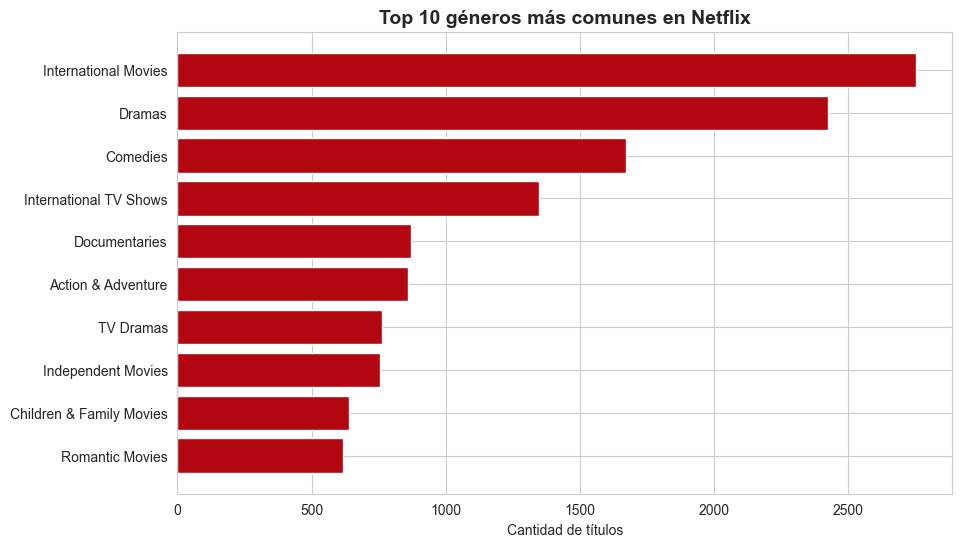

In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(top_generos.index[::-1], top_generos.values[::-1], color='#b20710')

ax.set_xlabel('Cantidad de títulos')
ax.set_title('Top 10 géneros más comunes en Netflix', fontweight='bold', fontsize=14)

plt.show()


## ¿Cuál es la duración promedio de películas vs. número de temporadas de series?

In [15]:
# Filtra solo las películas y calcula el promedio de duración en minutos
promedio_peliculas = df[df['type'] == 'Movie']['duration_int'].mean()

# Filtra solo las series y calcula el promedio de temporadas
promedio_series = df[df['type'] == 'TV Show']['duration_int'].mean()

print(f"Duración promedio de películas: {promedio_peliculas:.1f} minutos")
print(f"Promedio de temporadas en series: {promedio_series:.1f} temporadas")


Duración promedio de películas: 99.6 minutos
Promedio de temporadas en series: 1.8 temporadas


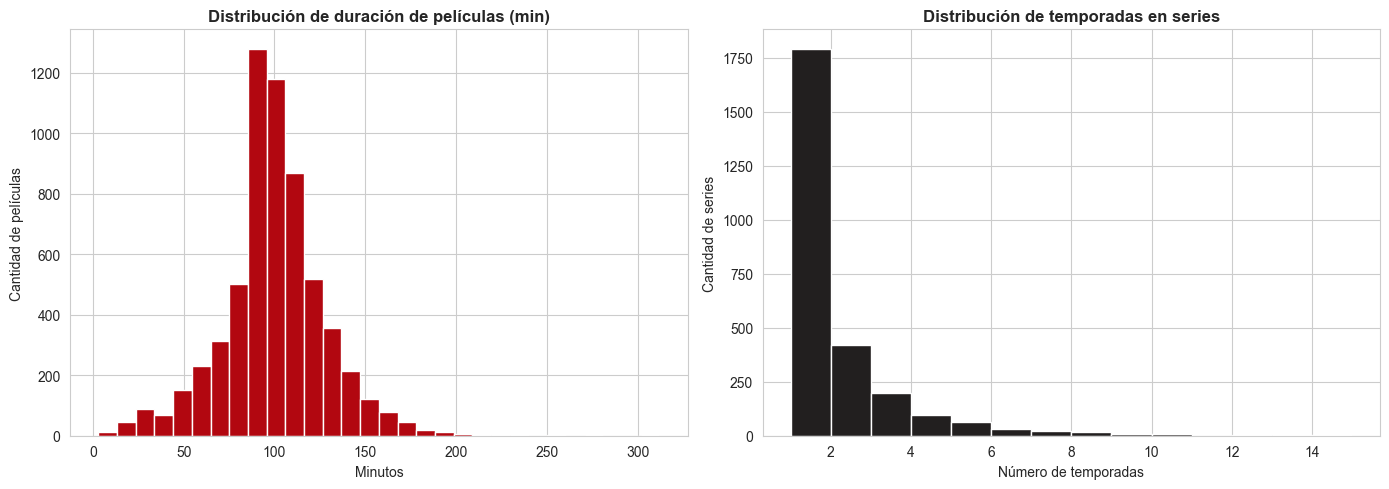

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma de duración de películas
axes[0].hist(df[df['type'] == 'Movie']['duration_int'], bins=30, color='#b20710')
axes[0].set_title('Distribución de duración de películas (min)', fontweight='bold')
axes[0].set_xlabel('Minutos')
axes[0].set_ylabel('Cantidad de películas')

# Histograma de temporadas de series
axes[1].hist(df[df['type'] == 'TV Show']['duration_int'], bins=range(1, 16), color='#221f1f')
axes[1].set_title('Distribución de temporadas en series', fontweight='bold')
axes[1].set_xlabel('Número de temporadas')
axes[1].set_ylabel('Cantidad de series')

plt.tight_layout()
plt.show()


## ¿Qué clasificaciones (rating) predominan?

In [17]:
# Cuenta cuántos títulos hay por cada clasificación
conteo_rating = df['rating'].value_counts()
print(conteo_rating)


rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


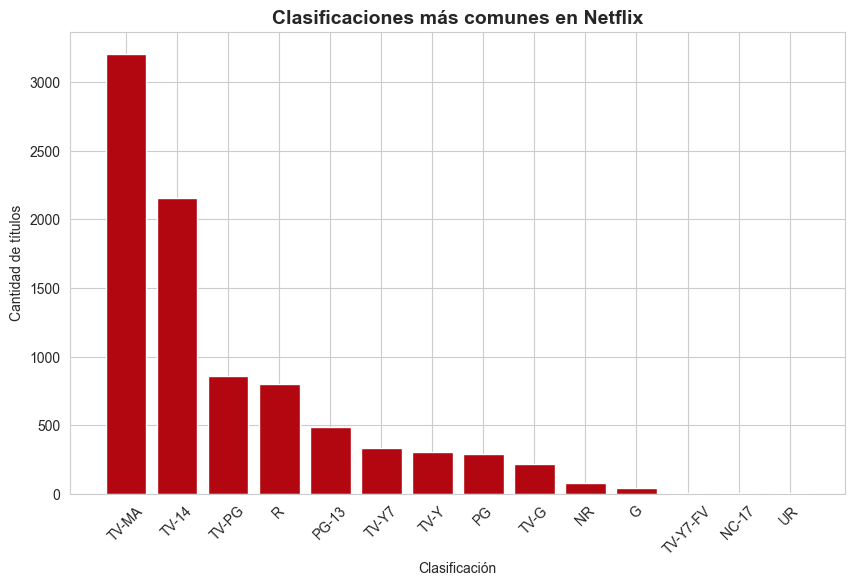

In [18]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(conteo_rating.index, conteo_rating.values, color='#b20710')

ax.set_xlabel('Clasificación')
ax.set_ylabel('Cantidad de títulos')
ax.set_title('Clasificaciones más comunes en Netflix', fontweight='bold', fontsize=14)
plt.xticks(rotation=45)

plt.show()


In [36]:
%pip install scikit-learn

# Convierte el texto de 'listed_in' en una lista limpia de géneros por fila
df['genre'] = df['listed_in'].apply(lambda x: x.replace(' ,',',').replace(', ',',').split(','))

test = df['genre']

# Convierte la lista de géneros en columnas binarias (0/1)
mlb = MultiLabelBinarizer()
res = pd.DataFrame(mlb.fit_transform(test), columns=mlb.classes_, index=test.index)

# Calcula la correlación entre todas las columnas de géneros
corr = res.corr()

# Máscara para ocultar la mitad superior del heatmap (es simétrico)
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True


ModuleNotFoundError: No module named 'sklearn'